In [1]:
import sys; sys.path.append("..")
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from src.data import load_data
from src.config import RANDOM_STATE, CV_DIR
from src.experiment_log import ExperimentLogger

X_train, _, y_train, _, labels = load_data()
lg = ExperimentLogger("tuan")

param_dist = {
    "n_estimators": [100, 200, 400],
    "max_depth": [10, 20, 40, None],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rs = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
    param_dist, n_iter=20, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=1, verbose=2)
rs.fit(X_train, y_train)

pd.DataFrame(rs.cv_results_).to_csv(CV_DIR / "tuning_rf_random.csv", index=False)
print("best_params:", rs.best_params_)
print("best_score :", round(rs.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END class_weight=balanced, max_depth=10, max_features=0.5, min_samples_leaf=5, n_estimators=100; total time=   3.2s
[CV] END class_weight=balanced, max_depth=10, max_features=0.5, min_samples_leaf=5, n_estimators=100; total time=   3.7s
[CV] END class_weight=balanced, max_depth=10, max_features=0.5, min_samples_leaf=5, n_estimators=100; total time=   4.8s
[CV] END class_weight=balanced, max_depth=10, max_features=0.5, min_samples_leaf=5, n_estimators=100; total time=   3.4s
[CV] END class_weight=balanced, max_depth=10, max_features=0.5, min_samples_leaf=5, n_estimators=100; total time=   3.8s
[CV] END class_weight=balanced, max_depth=10, max_features=sqrt, min_samples_leaf=1, n_estimators=100; total time=   1.2s
[CV] END class_weight=balanced, max_depth=10, max_features=sqrt, min_samples_leaf=1, n_estimators=100; total time=   1.1s
[CV] END class_weight=balanced, max_depth=10, max_features=sqrt, min_samples_leaf=1, n_es

In [2]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [20, 40],
    "min_samples_leaf": [1, 2],
    "class_weight": [rs.best_params_["class_weight"]],
    "max_features": [rs.best_params_["max_features"]],
}
gs = GridSearchCV(
    RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
    param_grid, scoring="f1_macro", cv=cv, n_jobs=1, verbose=2)
gs.fit(X_train, y_train)

pd.DataFrame(gs.cv_results_).to_csv(CV_DIR / "tuning_rf_grid.csv", index=False)
print("best_params:", gs.best_params_)
print("best_score :", round(gs.best_score_, 4))

Fitting 5 folds for each of 8 candidates, totalling 40 fits
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   1.7s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   1.8s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   1.6s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   1.7s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=200; total time=   1.7s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=400; total time=   3.3s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=400; total time=   3.6s
[CV] END class_weight=None, max_depth=20, max_features=log2, min_samples_leaf=1, n_estimators=400; total time=   3

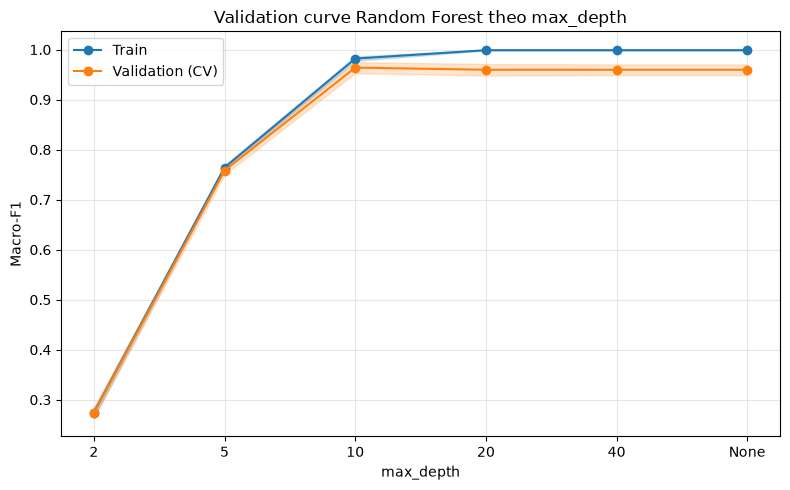

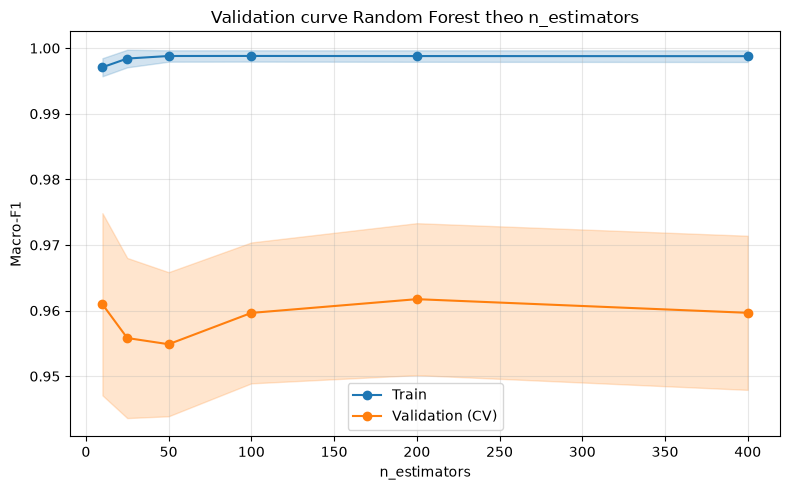

(array([[0.99741257, 0.99684106, 0.99953334, 0.99605982, 0.99558042],
        [0.9980712 , 0.99985205, 0.99983464, 0.99803675, 0.99625817],
        [0.9980712 , 0.99986909, 0.99985169, 0.99803674, 0.99816765],
        [0.99807084, 0.99986909, 0.99985169, 0.99805379, 0.99818469],
        [0.99807084, 0.99986909, 0.99985169, 0.99805379, 0.99810591],
        [0.99807084, 0.99986909, 0.99985169, 0.997975  , 0.99810591]]),
 array([[0.97115843, 0.93896212, 0.95670295, 0.97967471, 0.95831688],
        [0.9642432 , 0.93902489, 0.949065  , 0.97413446, 0.95263024],
        [0.9667107 , 0.9378895 , 0.9512771 , 0.96709053, 0.95140157],
        [0.96677881, 0.94023696, 0.95974079, 0.97183967, 0.95963979],
        [0.96919046, 0.94040633, 0.95974079, 0.97351567, 0.96585456],
        [0.96912237, 0.93909819, 0.95974079, 0.97280149, 0.95754812]]))

In [3]:
import sys
sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from src.data import load_data
from src.config import RANDOM_STATE, FIG_DIR

# Tải dữ liệu và khởi tạo chiến lược Cross-Validation
X_train, _, y_train, _, labels = load_data()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def plot_vc(param_name, param_range, base_params, fname, xlabel, log_x=False):
    # Khởi tạo mô hình Random Forest với các tham số cơ sở
    rf = RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, **base_params)
    
    # Xử lý riêng cho trường hợp max_depth có giá trị None (vì vẽ biểu đồ không hiểu None)
    if param_name == "max_depth":
        # Đổi None thành một số nguyên lớn (ví dụ 100) để vẽ, nhưng giữ nguyên param_range để gán nhãn
        plot_range = []
        for p in param_range:
            if p is None:
                plot_range.append(100)
            else:
                plot_range.append(p)
    else:
        plot_range = param_range

    # Tính toán validation curve
    train_scores, val_scores = validation_curve(
        rf, X_train, y_train, 
        param_name=param_name,
        param_range=param_range, 
        scoring="f1_macro", 
        cv=cv, 
        n_jobs=1
    )
    
    # Xác định vị trí các điểm trên trục x
    if param_name == "max_depth":
        x_positions = np.arange(len(param_range))
    else:
        x_positions = param_range

    # Vẽ biểu đồ
    fig, ax = plt.subplots(figsize=(8, 5))
    
    # Vẽ đường Train
    train_mean = train_scores.mean(axis=1)
    train_std = train_scores.std(axis=1)
    ax.plot(x_positions, train_mean, "o-", label="Train", color="tab:blue")
    ax.fill_between(x_positions, train_mean - train_std, train_mean + train_std, alpha=0.2, color="tab:blue")
    
    # Vẽ đường Validation (CV)
    val_mean = val_scores.mean(axis=1)
    val_std = val_scores.std(axis=1)
    ax.plot(x_positions, val_mean, "o-", label="Validation (CV)", color="tab:orange")
    ax.fill_between(x_positions, val_mean - val_std, val_mean + val_std, alpha=0.2, color="tab:orange")
    
    # Tùy chỉnh nhãn trục x nếu là max_depth
    if param_name == "max_depth":
        ax.set_xticks(x_positions)
        ax.set_xticklabels([str(p) for p in param_range])
        
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Macro-F1")
    ax.set_title(f"Validation curve Random Forest theo {param_name}")
    ax.grid(alpha=0.3)
    ax.legend()
    
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()
    
    return train_scores, val_scores

# 1) Khảo sát theo max_depth (cố định n_estimators=100)
depth_range = [2, 5, 10, 20, 40, None]
plot_vc(
    param_name="max_depth",
param_range=depth_range, 
    base_params={"n_estimators": 100},
    fname="rf_validation_curve_max_depth.png", 
    xlabel="max_depth"
)

# 2) Khảo sát theo n_estimators (để max_depth mặc định)
n_range = [10, 25, 50, 100, 200, 400]
plot_vc(
    param_name="n_estimators", 
    param_range=n_range, 
    base_params={},
    fname="rf_validation_curve_n_estimators.png", 
    xlabel="n_estimators"
)

In [4]:
best_rf = clone(gs.best_estimator_)
cw = gs.best_params_["class_weight"]

lg.run(best_rf, X_train, y_train, "tuan",
       strategy=f"class_weight={cw}",
       notes=f"RandomizedSearch(n_iter=20)+Grid; best_cv_macro_f1={gs.best_score_:.4f}")

,accuracy,balanced_acc,macro_f1,weighted_f1,mcc,recall_c0,recall_c1,recall_c2,recall_c3,recall_c4,...,recall_c6,recall_c7,recall_c8,recall_c9,recall_c10,recall_c11,model,fold,fit_time,pred_time
0,0.998092,0.957579,0.966672,0.998088,0.995295,0.987705,0.976471,1.0,0.996979,0.833333,...,1.0,1.000000,0.987893,1.000000,0.994286,0.914286,tuan,0,3.194090,0.217844
1,0.997933,0.929345,0.939030,0.997913,0.994906,0.997541,0.976471,1.0,1.000000,0.500000,...,1.0,0.993789,0.990315,0.996885,0.982857,0.914286,tuan,1,3.494375,0.239506
2,0.998410,0.954901,0.959809,0.998412,0.996079,0.994262,0.976744,1.0,1.000000,0.800000,...,1.0,0.993789,0.983051,0.996885,0.992653,0.971429,tuan,2,3.296275,0.216872
3,0.998304,0.975100,0.972666,0.998309,0.995818,0.994262,0.988235,1.0,0.996983,0.833333,...,1.0,1.000000,0.983092,1.000000,0.991013,0.914286,tuan,3,3.552940,0.329195
4,0.998251,0.948217,0.966789,0.998238,0.995688,0.995082,0.964706,1.0,0.998492,0.833333,...,1.0,1.000000,0.992754,0.996894,0.990196,0.857143,tuan,4,3.394180,0.216638


In [5]:
from src.experiment_log import export_excel
export_excel()

WindowsPath('C:/Users/w10/SGU26K2_MayHoc/DeTaiCuoiKy_V2/results/logs/experiment_log.xlsx')

In [6]:
import glob
df = pd.concat([pd.read_csv(f) for f in glob.glob("../results/logs/log_*.csv")])
df = df.drop_duplicates(subset=["Ten mo hinh", "Tham so (Hyperparameters)", "Random Seed", "Git commit"])

In [7]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
import pandas as pd

cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=100, max_depth=10, max_features="log2",
                            n_jobs=-1, random_state=RANDOM_STATE)
pred = cross_val_predict(rf, X_train, y_train, cv=cv)

cm = pd.DataFrame(confusion_matrix(y_train, pred), index=labels, columns=labels)
rare = ["Metasploit_Brute_Force_SSH", "NMAP_FIN_SCAN", "Wipro_bulb"]
print(cm.loc[rare].loc[:, (cm.loc[rare] != 0).any()])   # cac lop bi nham sang

# Co mau nao co dac trung GIONG HET nhung nhan KHAC nhau khong?
tmp = X_train.copy(); tmp["y"] = y_train.values
dup = tmp[tmp.duplicated(subset=X_train.columns.tolist(), keep=False)]
conflict = dup.groupby(X_train.columns.tolist())["y"].nunique()
print("So nhom dac trung giong het nhung khac nhan:", int((conflict > 1).sum()))

                            ARP_poisioning  DDOS_Slowloris  MQTT_Publish  \
Metasploit_Brute_Force_SSH               5               0             0   
NMAP_FIN_SCAN                            3               0             0   
Wipro_bulb                               3               2             1   

                            Metasploit_Brute_Force_SSH  NMAP_FIN_SCAN  \
Metasploit_Brute_Force_SSH                          22              0   
NMAP_FIN_SCAN                                        0             18   
Wipro_bulb                                           0              0   

                            NMAP_UDP_SCAN  Thing_Speak  Wipro_bulb  
Metasploit_Brute_Force_SSH              1            1           0  
NMAP_FIN_SCAN                           0            1           0  
Wipro_bulb                              2           10         157  
So nhom dac trung giong het nhung khac nhan: 3


In [9]:
lg = ExperimentLogger("tuan")
best_rf = RandomForestClassifier(n_estimators=100, max_depth=10, max_features="log2",
                                 min_samples_leaf=1, class_weight=None,
                                 n_jobs=-1, random_state=RANDOM_STATE)
lg.run(best_rf, X_train, y_train, "random_forest_tuned",
       strategy="Khong xu ly",
       notes="RandomizedSearch n_iter=20, best_cv=0.9630; khong cai thien co y nghia so voi mac dinh")

,accuracy,balanced_acc,macro_f1,weighted_f1,mcc,recall_c0,recall_c1,recall_c2,recall_c3,recall_c4,...,recall_c6,recall_c7,recall_c8,recall_c9,recall_c10,recall_c11,model,fold,fit_time,pred_time
0,0.997615,0.953742,0.964306,0.997608,0.994119,0.986885,0.964706,1.0,0.996979,0.833333,...,1.0,1.000000,0.987893,1.000000,0.989388,0.885714,random_forest_tuned,0,0.826039,0.070086
1,0.997562,0.926421,0.944651,0.997539,0.993991,0.993443,0.976471,1.0,1.000000,0.500000,...,1.0,0.993789,0.987893,0.996885,0.982857,0.885714,random_forest_tuned,1,0.911346,0.069271
2,0.997721,0.952982,0.958142,0.997725,0.994382,0.993443,0.965116,1.0,1.000000,0.800000,...,1.0,0.993789,0.980630,0.996885,0.984490,0.971429,random_forest_tuned,2,0.888877,0.080021
3,0.997721,0.971068,0.980525,0.997716,0.994381,0.990984,0.976471,1.0,0.995475,0.833333,...,1.0,1.000000,0.983092,1.000000,0.987745,0.885714,random_forest_tuned,3,1.010168,0.086120
4,0.997721,0.947402,0.967397,0.997706,0.994380,0.990984,0.964706,1.0,0.998492,0.833333,...,1.0,1.000000,0.990338,0.996894,0.986928,0.857143,random_forest_tuned,4,0.983827,0.083709


In [11]:
for cw in [None, "balanced", "balanced_subsample"]:
    m = RandomForestClassifier(n_estimators=100, max_depth=10, max_features="log2",
                               class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE)
    lg.run(m, X_train, y_train, f"rf_d10_cw_{cw}",
           strategy=f"class_weight={cw}", notes="doi chung class_weight")